In [2]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, root_mean_squared_error
import matplotlib.pyplot as plt

In [ ]:
# ---------- Configuração ----------
WINDOW_SIZE = 36          # 24 passos * 5 min = 120 min de histórico
HORIZON     = 6           # 6 passos * 5 min = 30 min à frente
FEATURES = [
    "glucose_level",
    "glucose_delta_5",
    "glucose_delta_15",
    "glucose_delta_30",
    "glucose_ma_15",
    "glucose_ma_30",
    "glucose_std_30",
    "hora_sin",
    "hora_cos",
    "dia_sin",
    "dia_cos",
    "fim_de_semana",
    "madrugada",
    "pos_cafe",
    "pos_almoco",
    "pos_jantar",
    "meal_carbs",
    "bolus_dose",
    "basal",
    "iob", 
    "cob"]
TARGET_COL  = "target"
BATCH_SIZE  = 64
EPOCHS      = 100
SEED        = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)


def get_csv_root():
    try:
        BASE_DIR = os.path.dirname(os.path.abspath(__file__))
    except NameError:
        BASE_DIR = os.getcwd()
    return os.path.join(BASE_DIR, "..", "processado")

In [4]:
def criar_janelas(df, features, target_col, window, horizon):
    X_list, y_list = [], []

    for pid in df["id_patient"].unique():
        sub = df[df["id_patient"] == pid].reset_index(drop=True)

        # Imputa 0 exceto glucose_level (o preditor principal não pode ser imputado)
        for f in features:
            if f != "glucose_level":
                sub[f] = sub[f].fillna(0)

        feats  = sub[features].values.astype(np.float32)
        target = sub[target_col].values.astype(np.float32)
        glicose_idx = features.index("glucose_level")

        # A janela precisa de: window passos antes + horizon passos pra frente.
        # Como a coluna "target" já está deslocada em 30 min (HORIZON passos),
        # o target na linha i JÁ é o valor futuro.
        for i in range(window, len(sub)):
            y_val = target[i]

            # pula se target for NaN
            if np.isnan(y_val):
                continue

            janela = feats[i - window:i]

            # pula se a janela tiver qualquer NaN em glucose_level
            if np.isnan(janela[:, glicose_idx]).any():
                continue

            X_list.append(janela)
            y_list.append(y_val)

    return np.array(X_list), np.array(y_list)

In [5]:
def criar_modelo(window_size, n_features):
    model = models.Sequential([
        layers.Input(shape=(window_size, n_features)),

        # LSTM: 64 unidades, retorna apenas o último output
        layers.LSTM(64, return_sequences=False),

        # Dropout para regularizar
        layers.Dropout(0.2),

        # Camada densa intermediária
        layers.Dense(32, activation="relu"),

        # Saída: um único valor (glicose em mg/dL)
        layers.Dense(1),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",          # MSE para regressão
        metrics=["mae"],
    )
    return model

In [6]:
def adicionar_features_temporais(df):
    """Transforma 'ts' em features numéricas cíclicas e flags."""
    df = df.copy()
    dt = pd.to_datetime(df["ts"])

    # Hora do dia (cíclica)
    h = dt.dt.hour + dt.dt.minute / 60
    df["hora_sin"] = np.sin(2 * np.pi * h / 24)
    df["hora_cos"] = np.cos(2 * np.pi * h / 24)

    # Dia da semana (cíclico)
    d = dt.dt.dayofweek
    df["dia_sin"] = np.sin(2 * np.pi * d / 7)
    df["dia_cos"] = np.cos(2 * np.pi * d / 7)

    # Flags
    df["fim_de_semana"] = (d >= 5).astype(int)
    df["madrugada"]     = dt.dt.hour.isin([0, 1, 2, 3, 4, 5]).astype(int)
    df["pos_cafe"]      = dt.dt.hour.between(7, 10).astype(int)
    df["pos_almoco"]    = dt.dt.hour.between(12, 15).astype(int)
    df["pos_jantar"]    = dt.dt.hour.between(19, 22).astype(int)

    return df

In [7]:
# ---- 1. Carregar ----
df_tr = pd.read_csv(os.path.join(get_csv_root(), "treinamento_final.csv"))
df_val = pd.read_csv(os.path.join(get_csv_root(), "testes_final.csv"))

df_tr["ts"]  = pd.to_datetime(df_tr["ts"])
df_val["ts"] = pd.to_datetime(df_val["ts"])

df_tr  = adicionar_features_temporais(df_tr)
df_val = adicionar_features_temporais(df_val)

In [8]:
# ---------- 2. Criar janelas por paciente ----------
X_tr, y_tr = criar_janelas(df_tr,  FEATURES, TARGET_COL, WINDOW_SIZE, HORIZON)
X_val, y_val = criar_janelas(df_val, FEATURES, TARGET_COL, WINDOW_SIZE, HORIZON)

print(f"Treino: {X_tr.shape} | Val: {X_val.shape}")
print(f"y_tr: {y_tr.shape} | y_val: {y_val.shape}")

Treino: (130961, 36, 24) | Val: (30384, 36, 24)
y_tr: (130961,) | y_val: (30384,)


In [9]:
# ---------- 3. Normalização ----------
n_features = len(FEATURES)

scaler = StandardScaler()
scaler.fit(X_tr.reshape(-1, n_features))

X_tr_scaled  = scaler.transform(X_tr.reshape(-1, n_features)).reshape(X_tr.shape)
X_val_scaled = scaler.transform(X_val.reshape(-1, n_features)).reshape(X_val.shape)

In [10]:
# ---------- 4. Modelo ----------
model = criar_modelo(WINDOW_SIZE, n_features)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        22,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,897 (97.25 KB)

 Trainable params: 24,897 (97.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# ---------- 5. Treino ----------
callbacks = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
]

history = model.fit(
    X_tr_scaled, y_tr,
    validation_data=(X_val_scaled, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/100
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - loss: 3602.5769 - mae: 41.2942 - val_loss: 1242.4502 - val_mae: 26.1290 - learning_rate: 0.0010
Epoch 2/100
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - loss: 1442.9730 - mae: 28.1976 - val_loss: 1208.2620 - val_mae: 25.8204 - learning_rate: 0.0010
Epoch 3/100
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - loss: 1376.3340 - mae: 27.5704 - val_loss: 1176.3126 - val_mae: 25.3599 - learning_rate: 0.0010
Epoch 4/100
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - loss: 1316.4655 - mae: 26.9643 - val_loss: 1180.6528 - val_mae: 25.3314 - learning_rate: 0.0010
Epoch 5/100
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - loss: 1271.9047 - mae: 26.5117 - val_loss: 1178.0857 - val_mae: 25.3505 - learning_rate: 0.0010
Epoch 6/100
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - loss: 1228.0243 - mae: 26.0763 - val_loss: 1183.0349 - val_mae: 25.4157 - learning_rate: 0.0010
Epoch 7/100
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - loss: 1182.

In [ ]:
# ---------- 6. Avaliação ----------
y_pred = model.predict(X_val_scaled).flatten()

rmse_lstm = root_mean_squared_error(y_val, y_pred)
mae_lstm  = np.mean(np.abs(y_val - y_pred))
rmse_pers = root_mean_squared_error(y_val, X_val[:, -1, 0])

print()
print(f"LSTM       — RMSE: {rmse_lstm:.2f} | MAE: {mae_lstm:.2f}")
print(f"Persistência — RMSE: {rmse_pers:.2f}")
# print(f"RF baseline — RMSE: 19.55 (referência)")

950/950 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step

LSTM       — RMSE: 34.30 | MAE: 25.36
Persistência — RMSE: 41.01
RF baseline — RMSE: 19.55 (referência)


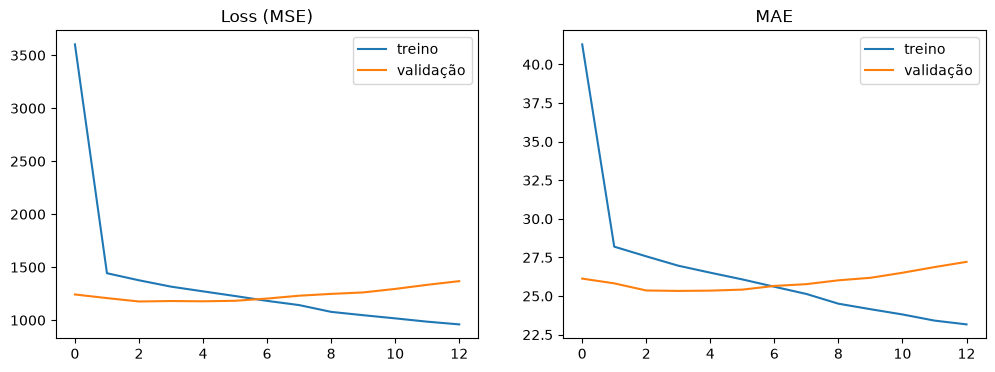

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history["loss"], label="treino")
ax1.plot(history.history["val_loss"], label="validação")
ax1.set_title("Loss (MSE)")
ax1.legend()

ax2.plot(history.history["mae"], label="treino")
ax2.plot(history.history["val_mae"], label="validação")
ax2.set_title("MAE")
ax2.legend()

plt.show()

In [14]:
# ---------- 7. Salvar ----------
model.save("modelo_lstm.keras")
joblib.dump(scaler, "scaler_lstm.pkl")
print("Modelo salvo em modelo_lstm.keras")

Modelo salvo em modelo_lstm.keras
